# Task 2 – History and calendar features (Maram)
**Input:** `food_clean.csv` (from `Task2_Cleaning.ipynb`, run that first)  
**Output:** `maram_features.csv`, the history and calendar columns, joined with Joud's columns at the end of the week.

In [45]:
import pandas as pd

We only need pandas here.

In [46]:
df = pd.read_csv('food_clean.csv')
df['Inspection Date'] = pd.to_datetime(df['Inspection Date'])
df['First_Seen_Date'] = pd.to_datetime(df['First_Seen_Date'])
print(df.shape)

(212463, 22)


We read the clean file. The date becomes text again when saved to CSV, so we change it back to a real date.

In [47]:
# M1: sort each business's inspections from oldest to newest
df = df.sort_values(by=['Business_ID', 'Inspection Date'])
df[['Business_ID', 'Inspection Date', 'Results']].head(10)

,Business_ID,Inspection Date,Results
198578,1000049_PEREZ MEXICAN FOOD,2010-10-18,Fail
198241,1000049_PEREZ MEXICAN FOOD,2010-10-25,Pass
180267,1000049_PEREZ MEXICAN FOOD,2011-11-15,Pass w/ Conditions
168293,1000049_PEREZ MEXICAN FOOD,2012-08-15,Pass
150563,1000049_PEREZ MEXICAN FOOD,2013-09-09,Fail
150092,1000049_PEREZ MEXICAN FOOD,2013-09-17,Pass
141090,1000049_PEREZ MEXICAN FOOD,2014-04-04,Fail
140472,1000049_PEREZ MEXICAN FOOD,2014-04-16,Pass
128375,1000049_PEREZ MEXICAN FOOD,2014-11-24,Pass
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,Pass w/ Conditions


**M1.** We sort by Business_ID and then by date, so the inspections of one business are next to each other, oldest first. The next steps need this order.

In [48]:
# M2: did this business fail its previous inspection?
df['Prev_Fail'] = df.groupby('Business_ID')['Fail'].shift(1)
df[['Business_ID', 'Inspection Date', 'Fail', 'Prev_Fail']].head(10)

,Business_ID,Inspection Date,Fail,Prev_Fail
198578,1000049_PEREZ MEXICAN FOOD,2010-10-18,1,NaN
198241,1000049_PEREZ MEXICAN FOOD,2010-10-25,0,1.0
180267,1000049_PEREZ MEXICAN FOOD,2011-11-15,0,0.0
168293,1000049_PEREZ MEXICAN FOOD,2012-08-15,0,0.0
150563,1000049_PEREZ MEXICAN FOOD,2013-09-09,1,0.0
150092,1000049_PEREZ MEXICAN FOOD,2013-09-17,0,1.0
141090,1000049_PEREZ MEXICAN FOOD,2014-04-04,1,0.0
140472,1000049_PEREZ MEXICAN FOOD,2014-04-16,0,1.0
128375,1000049_PEREZ MEXICAN FOOD,2014-11-24,0,0.0
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,0,0.0


**M2.** `shift(1)` is new for us: it moves the column down by one row, so each inspection gets the result of the inspection before it. `groupby('Business_ID')` makes sure it only looks inside the same business. The first inspection of each business has nothing before it, so it gets an empty value (NaN).

In [49]:
df['First_Inspection'] = df['Prev_Fail'].isnull().apply(lambda x: 1 if x else 0)
df['Prev_Fail'] = df['Prev_Fail'].fillna(0)
df['First_Inspection'].value_counts()

First_Inspection
0    174167
1     38296
Name: count, dtype: int64

We save "is this the first inspection we have for this business?" in its own column (1 = yes), then fill the empty Prev_Fail with 0. This way the model still knows which rows had no history. Because the history now starts in 2010, a business only gets First_Inspection = 1 at its real first visit in the data. **(Update the numbers after running.)**

In [50]:
# M3: days since the last inspection of the same business
df['Days_Since_Last'] = df.groupby('Business_ID')['Inspection Date'].diff().dt.days
df['Days_Since_Last'].describe()

count    174167.000000
mean        251.626140
std         259.646432
min           1.000000
25%          14.000000
50%         231.000000
75%         372.000000
max        4432.000000
Name: Days_Since_Last, dtype: float64

**M3.** `diff()` and `.dt.days` are new for us: `diff()` subtracts the previous date from this date (inside the same business), and `.dt.days` turns the result into a number of days. First inspections have no previous date, so they are empty. Median number of days is 231.

In [51]:
median_days = df['Days_Since_Last'].median()
df['Days_Since_Last'] = df['Days_Since_Last'].fillna(median_days)
print(median_days)

231.0


We fill the empty values (first inspections) with the median, because the median is not affected by very long gaps. The First_Inspection column still tells the model these rows were filled.

In [52]:
# M4: month of the inspection
df['Month'] = df['Inspection Date'].dt.month
df['Month'].value_counts().sort_index()

Month
1     16762
2     15526
3     18893
4     18091
5     19734
6     19595
7     15974
8     18681
9     18915
10    19186
11    16514
12    14592
Name: count, dtype: int64

**M4.** The month (1–12). Hot months may have more temperature problems; the Chicago model also used temperature.

In [53]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['Season'] = df['Month'].apply(get_season)
df['Season'].value_counts()

Season
Spring    56718
Fall      54615
Summer    54250
Winter    46880
Name: count, dtype: int64

We group the months into seasons with a def + apply, like we did in the labs.

In [54]:
# M5: keep the 8 most common facility types, the rest becomes 'Other'
top8 = df['Facility Type'].value_counts().head(8).index
top8

Index(['Restaurant', 'Grocery Store', 'School', 'Children's Services Facility',
       'Bakery', 'Daycare Above and Under 2 Years', 'Daycare (2 - 6 Years)',
       'Long Term Care'],
      dtype='str', name='Facility Type')

**M5.** There are many facility types and most have very few rows. We keep the 8 most common ones (written above).

In [55]:
def group_facility(t):
    if t in top8:
        return t
    else:
        return 'Other'

df['Facility_Group'] = df['Facility Type'].apply(group_facility)
df['Facility_Group'].value_counts()

Facility_Group
Restaurant                         143557
Grocery Store                       27346
School                              14971
Other                               11416
Children's Services Facility         4975
Bakery                               3115
Daycare Above and Under 2 Years      2960
Daycare (2 - 6 Years)                2451
Long Term Care                       1672
Name: count, dtype: int64

Every other type becomes "Other", the same idea as grouping small categories in the Kindle assignment. Later, for the model, we will turn this column into numbers with `get_dummies`.

In [56]:
# M6: Inspection_Group
def group_inspection(t):
    t = str(t).lower()
    if 'canvass' in t:
        return 'Canvass'
    elif 'license' in t:
        return 'License'
    elif 'complaint' in t or 'poisoning' in t:
        return 'Complaint'
    else:
        return 'Other'

df['Inspection_Group'] = df['Inspection Type'].apply(group_inspection)
df['Inspection_Group'].value_counts()

Inspection_Group
Canvass      128803
License       40661
Complaint     40602
Other          2397
Name: count, dtype: int64

**M6.** Grouping inspection types into 4 categories Canvass, Complaint, License and Other.

| Group | Inspection Types |
| ----- | ---------------- |
| Canvass | Canvass and Canvass Re-Inspection |
| Complaint | Complaint, Complaint Re-Inspection, Short Form Complaint, Suspected Food Poisoning, … |
| License | License and License Re-Inspection |
| Other | Consultation, Recent Inspection, Tag Removal, … |

Note that Re-Inspections are not split into separate groups as they are to be handled at `Is_Reinspection` column.

In [57]:
# M7: risk as a number
def risk_number(r):
    if r == 'Risk 1 (High)':
        return 1
    elif r == 'Risk 2 (Medium)':
        return 2
    elif r == 'Risk 3 (Low)':
        return 3
    else:
        return 0

df['Risk_Num'] = df['Risk'].apply(risk_number)
df['Risk_Num'].value_counts()

Risk_Num
1    158457
2     39046
3     14942
0        18
Name: count, dtype: int64

**M7.** The model needs numbers, so Risk 1 (High) = 1, Risk 2 = 2, Risk 3 (Low) = 3, and Unknown = 0.

In [58]:
# M8: placebo period: a fake change date (1 Jan 2017) inside the old-code years
def placebo_period(date):
    if date < pd.Timestamp('2017-01-01'):
        return 'Before 2017'
    else:
        return 'After 2017'

df['Placebo_Period'] = df['Inspection Date'].apply(placebo_period)
df['Placebo_Period'].value_counts()

Placebo_Period
Before 2017    123268
After 2017      89195
Name: count, dtype: int64

**M8.** For H3 we compare the real change (July 2018) with a fake one (January 2017), when nothing changed. If the model drops much more at 2018 than at 2017, the drop is caused by the new code. (Period with the grace period is already made in the cleaning notebook.)

In [59]:
# M9: Past_Fail_Rate, M10: Num_Past_Inspections
num_past = df.groupby('Business_ID').cumcount()
df['Past_Fail_Rate'] = ((df.groupby('Business_ID')['Fail'].cumsum() - df['Fail']) / num_past).fillna(0)
df['Num_Past_Inspections'] = num_past
df[['Business_ID', 'Inspection Date', 'Fail', 'Prev_Fail', 'Num_Past_Inspections', 'Past_Fail_Rate']].head(10)

,Business_ID,Inspection Date,Fail,Prev_Fail,Num_Past_Inspections,Past_Fail_Rate
198578,1000049_PEREZ MEXICAN FOOD,2010-10-18,1,0.0,0,0.000000
198241,1000049_PEREZ MEXICAN FOOD,2010-10-25,0,1.0,1,1.000000
180267,1000049_PEREZ MEXICAN FOOD,2011-11-15,0,0.0,2,0.500000
168293,1000049_PEREZ MEXICAN FOOD,2012-08-15,0,0.0,3,0.333333
150563,1000049_PEREZ MEXICAN FOOD,2013-09-09,1,0.0,4,0.250000
150092,1000049_PEREZ MEXICAN FOOD,2013-09-17,0,1.0,5,0.400000
141090,1000049_PEREZ MEXICAN FOOD,2014-04-04,1,0.0,6,0.333333
140472,1000049_PEREZ MEXICAN FOOD,2014-04-16,0,1.0,7,0.428571
128375,1000049_PEREZ MEXICAN FOOD,2014-11-24,0,0.0,8,0.375000
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,0,0.0,9,0.333333


**M9.** `Past_Fail_Rate` is the share of the earlier visits of the business that had a fail.

**M10.** `Num_Past_Inspections` keeps the count of earlier visits.

In [60]:
# M11: Days_Since_First_Seen
df['Days_Since_First_Seen'] = (df['Inspection Date'] - df['First_Seen_Date']).dt.days
df['Days_Since_First_Seen'].describe()

count    212463.000000
mean       1181.265670
std        1178.326922
min           0.000000
25%          62.000000
50%         855.000000
75%        1918.000000
max        4740.000000
Name: Days_Since_First_Seen, dtype: float64

**M11.** `Days_Since_First_Seen` is the assumed age of the facility. It is calculated from the date of first seen till the date of the inspection. We assume that the age of the facility is 0 on its first inspection date (first seen date).<br>Note that businesses older than 2010 looks as if they started in 2010 because the data starts in 2010.

In [61]:
df['Inspection Type'].unique()

<StringArray>
[                               'Canvass',
                  'Canvass Re-Inspection',
                              'Complaint',
                'Complaint Re-Inspection',
                        'OUT OF BUSINESS',
                           'Consultation',
                      'Recent Inspection',
                   'Short Form Complaint',
                                'License',
               'Suspected Food Poisoning',
 ...
        'CLOSE-UP/COMPLAINT REINSPECTION',
                      'Illegal Operation',
                   'CANVASS FOR RIB FEST',
                          'sfp/complaint',
 'LICENSE RENEWAL INSPECTION FOR DAYCARE',
                     'Special Task Force',
              'RE-INSPECTION OF CLOSE-UP',
                       'TASK FORCE NIGHT',
                      'SMOKING COMPLAINT',
                             'Kids Cafe'']
Length: 102, dtype: str

Check for the different inspection types present and how re-inspections are marked. Note that mostly it is written as Re-Inspection and once as Re-inspection. So, the criteria (regex) on which the inspection type is considered as re-inspection should be flexible to appeal different writing styles.

In [62]:
# M12: Is_Reinspection
df['Is_Reinspection'] = df['Inspection Type'].str.contains(r're-?insp', case=False, na=False)
df[['Business_ID','Inspection Date','Inspection Type','Is_Reinspection']].head(10)

,Business_ID,Inspection Date,Inspection Type,Is_Reinspection
198578,1000049_PEREZ MEXICAN FOOD,2010-10-18,Canvass,False
198241,1000049_PEREZ MEXICAN FOOD,2010-10-25,Canvass Re-Inspection,True
180267,1000049_PEREZ MEXICAN FOOD,2011-11-15,Canvass,False
168293,1000049_PEREZ MEXICAN FOOD,2012-08-15,Canvass,False
150563,1000049_PEREZ MEXICAN FOOD,2013-09-09,Canvass,False
150092,1000049_PEREZ MEXICAN FOOD,2013-09-17,Canvass Re-Inspection,True
141090,1000049_PEREZ MEXICAN FOOD,2014-04-04,Complaint,False
140472,1000049_PEREZ MEXICAN FOOD,2014-04-16,Complaint Re-Inspection,True
128375,1000049_PEREZ MEXICAN FOOD,2014-11-24,Canvass,False
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,Canvass,False


**M12.** `Is_Reinspection` checks if the `Inspection Type` contains "Re-Inspection" in different formats with or without -, uppercase or lowercase and if the value of `Inspection Type` is NaN it sets `Is_Reinspection` to False

In [63]:
# Check: Prev_Fail against this result (study years 2015-2022)
study = df[df['Year'] >= 2015]
pd.crosstab(study['Prev_Fail'], study['Fail'], normalize='index').round(3)

Fail,0,1
Prev_Fail,,
0.0,0.743,0.257
1.0,0.894,0.106


Quick check: if businesses that failed last time fail more often this time, Prev_Fail is a useful feature. If the facilities that failed before are **less** likely to fail again, this may be due to re-inspections (facilities usually pass the re-inspection). **(Update the numbers after running.)**

In [64]:
# Check: Prev_Fail against this result, re-inspections not included
pd.crosstab(study.loc[~study['Is_Reinspection'], 'Prev_Fail'], study.loc[~study['Is_Reinspection'], 'Fail'], normalize='index').round(3)

Fail,0,1
Prev_Fail,,
0.0,0.738,0.262
1.0,0.666,0.334


This check tests our assumption that re-inspections cause the surprising pattern above: without re-inspections, the facilities that failed before should be **more** likely to fail again. **(Update the numbers after running.)**

In [65]:
cols = ['Inspection ID', 'Prev_Fail', 'First_Inspection', 'Days_Since_Last',
        'Month', 'Season', 'Facility_Group', 'Inspection_Group', 'Risk_Num', 'Placebo_Period', 'Past_Fail_Rate', 'Num_Past_Inspections', 'Days_Since_First_Seen', 'Is_Reinspection']
df[cols].to_csv('maram_features.csv', index=False)
print(df[cols].shape)

(212463, 14)


We save only the ID and the new columns. At the end of the week this file is joined with Joud's file and the clean file on `Inspection ID`.

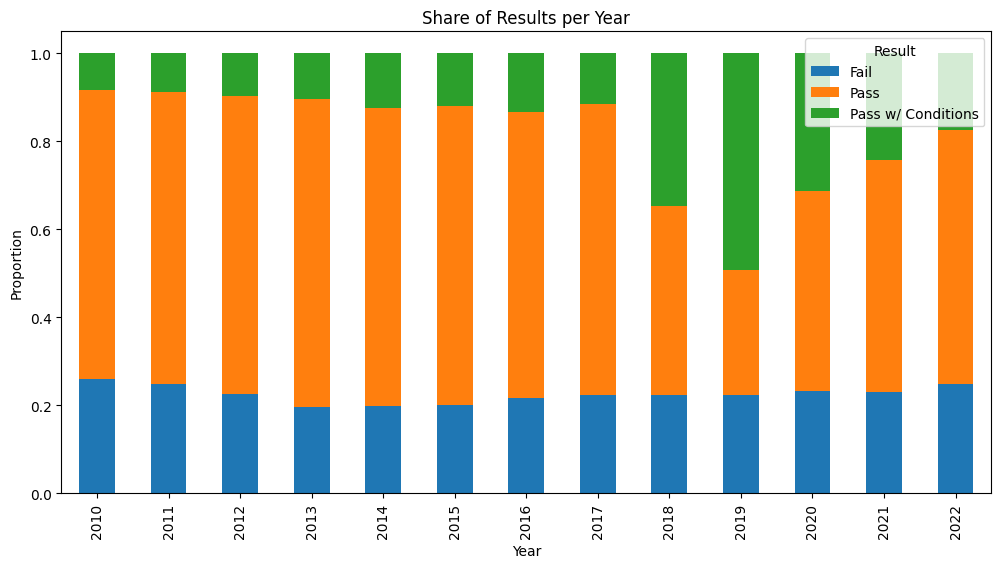

In [66]:
# share of each result in each year (each row adds up to 1)
import matplotlib.pyplot as plt
ct = pd.crosstab(df['Inspection Date'].dt.year, df['Results'])
year_share = ct.divide(ct.sum(axis='columns'), axis='rows')
year_share.plot.bar(stacked=True, figsize=(12, 6))
plt.title('Share of Results per Year')
plt.xlabel('Year')
plt.ylabel('Proportion')
plt.legend(title='Result')
plt.show()

This stacked bar plot supports the hypothesis that the change in violations affected how the inspections are handled. The fail rate stays about the same every year, but the share of Pass and Pass W/ Conditions changes a lot in 2018-2019, so it seems that the change mainly affected how facilities pass, not how often they fail.